# Домашнее задание 4.1. Метод стрельбы для линейного маятника

**Уровень:** 🟢  
**Выполнил:** Константин Мурусидзе, 6 курс мехмата МГУ

Начальная угловая скорость подбирается методами Ньютона и бисекцией.
Сравниваются число вычислений невязки и ошибка движения при разных шагах интегрирования.

## 1. Постановка задачи

$$
\ddot\theta+\theta=0,\qquad \theta(0)=0,\qquad \theta(2)=0.2.
$$

Неизвестный параметр — $s=\dot\theta(0)$.
При заданном $s$ интегрируется задача Коши
$\dot\theta=v$, $\dot v=-\theta$, $(\theta(0),v(0))=(0,s)$.
Затем вычисляется невязка

$$R_h(s)=\theta_h(2;s)-0.2.$$

Индекс $h$ подчёркивает, что невязка вычисляется численно, методом RK4.
Точное решение краевой задачи и точная начальная скорость:

$$
\theta_*(t)=\frac{0.2\sin t}{\sin 2},\qquad
s_* = \frac{0.2}{\sin 2}.
$$

In [6]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25})

T = 2.0
target = 0.2
s_exact = target/np.sin(T)
h_values = [0.2, 0.1, 0.05, 0.025]
root_tol = 1e-12


def rhs(state):
    theta, velocity = state
    return np.array([velocity, -theta])


def integrate(s, h):
    n_steps = int(np.ceil(T/h))
    time = np.linspace(0.0, T, n_steps + 1)
    states = np.empty((n_steps + 1, 2))
    states[0] = [0.0, s]

    for n, dt in enumerate(np.diff(time)):
        state = states[n]
        k1 = rhs(state)
        k2 = rhs(state + dt*k1/2)
        k3 = rhs(state + dt*k2/2)
        k4 = rhs(state + dt*k3)
        states[n + 1] = state + dt*(k1 + 2*k2 + 2*k3 + k4)/6
    return time, states


def exact_solution(time):
    return target*np.sin(time)/np.sin(T)


def make_residual(h):
    counter = {"calls": 0}

    def residual(s):
        counter["calls"] += 1
        _, states = integrate(s, h)
        return states[-1, 0] - target

    return residual, counter


print(f"Точная начальная скорость s* = {s_exact:.12f}")


Точная начальная скорость s* = 0.219950034059


## 2. Ньютон и бисекция

Для Ньютона:

$$
s_{k+1}=s_k-\frac{R_h(s_k)}{R'_h(s_k)},\qquad
R'_h(s)\approx\frac{R_h(s+\eta)-R_h(s-\eta)}{2\eta},\quad \eta=10^{-4}.
$$

Каждая численная производная требует двух дополнительных вычислений невязки.
Начальное приближение Ньютона: $s_0=0.5$.
Для бисекции выбирается интервал $[0,0.5]$, на концах которого невязки имеют разные знаки.
Оба метода останавливаются при $|R_h(s)|\le10^{-12}$.

Счётчик включает все вызовы невязки во время поиска корня, в том числе
проверки концов интервала и последнего приближения. Расчёты для построения графиков
в этот счётчик не включаются.

In [7]:
def newton(residual, s0, tol, eta=1e-4, max_iter=20):
    s = float(s0)
    value = residual(s)
    history = [(s, value)]

    for iteration in range(max_iter + 1):
        if abs(value) <= tol:
            return {"s": s, "R": value, "history": np.array(history),
                    "iterations": iteration}
        if iteration == max_iter:
            break
        derivative = (residual(s + eta) - residual(s - eta))/(2*eta)
        if abs(derivative) < 1e-14:
            raise RuntimeError("Слишком малая производная невязки")
        s -= value/derivative
        value = residual(s)
        history.append((s, value))
    raise RuntimeError("Ньютон не сошёлся за заданное число итераций")


def bisection(residual, left, right, tol, max_iter=100):
    f_left = residual(left)
    f_right = residual(right)
    if f_left*f_right >= 0.0:
        raise ValueError("Нужен интервал с разными знаками невязки на концах")
    history = []

    for iteration in range(1, max_iter + 1):
        middle = (left + right)/2
        value = residual(middle)
        history.append((middle, value))
        if abs(value) <= tol:
            return {"s": middle, "R": value, "history": np.array(history),
                    "iterations": iteration}
        if f_left*value < 0.0:
            right = middle
        else:
            left, f_left = middle, value
    raise RuntimeError("Бисекция не сошлась за заданное число итераций")


def shoot(h, method, tol=root_tol):
    residual, counter = make_residual(h)
    if method == "Newton":
        result = newton(residual, 0.5, tol)
    else:
        result = bisection(residual, 0.0, 0.5, tol)
    result["calls"] = counter["calls"]
    time, states = integrate(result["s"], h)
    result["time"], result["states"] = time, states
    result["error"] = states[:, 0] - exact_solution(time)
    return result


solutions = {}
print(f"{'h':>6} {'Метод':<10} {'s':>16} {'|R_h|':>12} {'max ошибка θ':>16} {'Итер.':>6} {'Вызовы R':>9}")
for h in h_values:
    # При каждом новом шаге начальная скорость подбирается заново.
    for method in ["Newton", "Bisection"]:
        result = shoot(h, method)
        solutions[(method, h)] = result
        print(f"{h:6.3f} {method:<10} {result['s']:16.12f} "
              f"{abs(result['R']):12.3e} {np.max(np.abs(result['error'])):16.6e} "
              f"{result['iterations']:6d} {result['calls']:9d}")

residual_demo, _ = make_residual(0.2)
print()
print(f"Для h=0.2: R(0)={residual_demo(0.0):.6f}, R(0.5)={residual_demo(0.5):.6f}")


     h Метод                     s        |R_h|     max ошибка θ  Итер.  Вызовы R
 0.200 Newton       0.219948360758    1.392e-13     3.379217e-06      1         4
 0.200 Bisection    0.219948360758    3.467e-13     3.379217e-06     37        39
 0.100 Newton       0.219949897399    8.094e-14     2.278755e-07      1         4
 0.100 Bisection    0.219949897399    1.828e-13     2.278758e-07     38        40
 0.050 Newton       0.219950024537    2.845e-14     1.467379e-08      1         4
 0.050 Bisection    0.219950024537    6.506e-14     1.467388e-08     37        39
 0.025 Newton       0.219950033433    4.373e-13     9.306793e-10      1         4
 0.025 Bisection    0.219950033434    7.619e-14     9.301827e-10     38        40

Для h=0.2: R(0)=-0.200000, R(0.5)=0.254652


## 3. Пристрелочные траектории и невязка

Пробные скорости дают разные углы в конечный момент.
Требуемое положение отмечено крестиком.
На графике невязки показаны все приближения обоих методов для $h=0.2$.

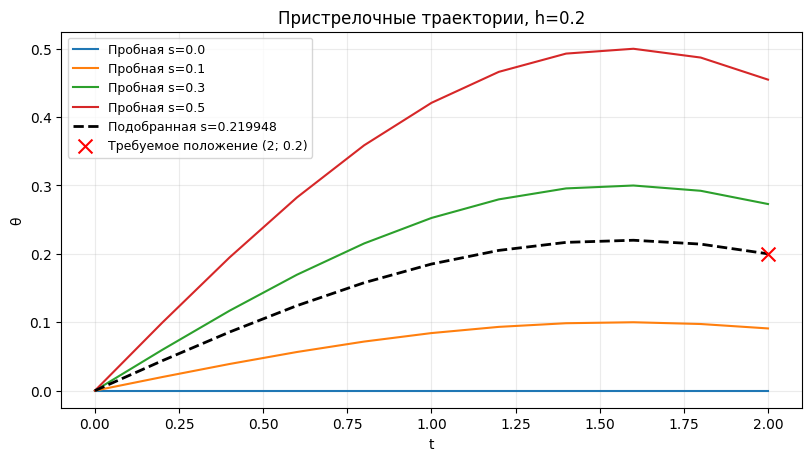

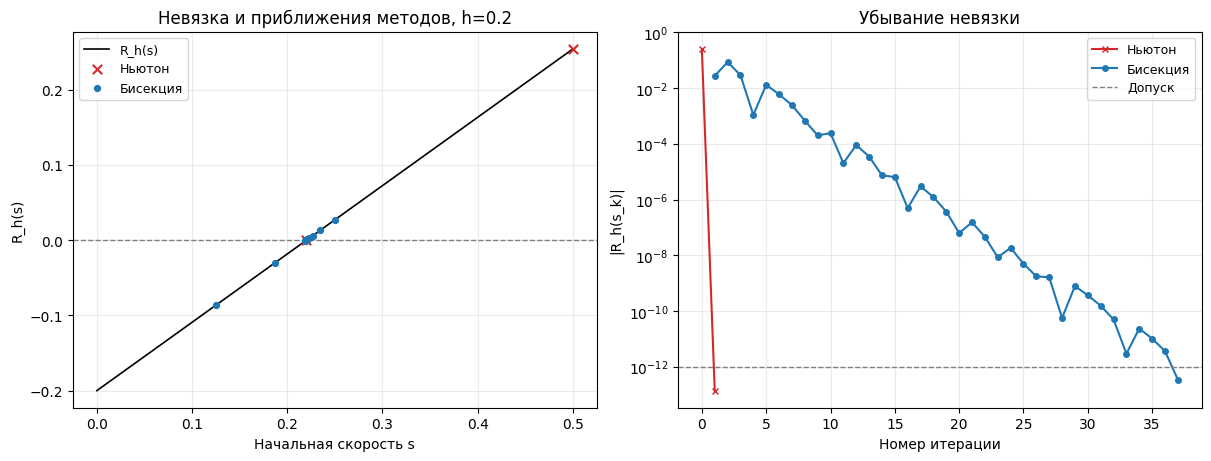

In [8]:
h_demo = 0.2
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for s in [0.0, 0.1, 0.3, 0.5]:
    time, states = integrate(s, h_demo)
    ax.plot(time, states[:, 0], label=f"Пробная s={s}")
selected = solutions[("Newton", h_demo)]
ax.plot(selected["time"], selected["states"][:, 0], "k--", lw=2,
        label=f"Подобранная s={selected['s']:.6f}")
ax.scatter([T], [target], marker="x", s=100, color="red", zorder=5,
           label="Требуемое положение (2; 0.2)")
ax.set_xlabel("t")
ax.set_ylabel("θ")
ax.set_title("Пристрелочные траектории, h=0.2")
ax.legend(fontsize=9)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
speeds = np.linspace(0.0, 0.5, 151)
residual_values = np.array([integrate(s, h_demo)[1][-1, 0] - target for s in speeds])
axes[0].plot(speeds, residual_values, color="black", lw=1.2, label="R_h(s)")
axes[0].axhline(0.0, color="gray", ls="--", lw=1)

for method, label, color, marker in [
        ("Newton", "Ньютон", "tab:red", "x"),
        ("Bisection", "Бисекция", "tab:blue", "o")]:
    history = solutions[(method, h_demo)]["history"]
    axes[0].scatter(history[:, 0], history[:, 1], color=color, marker=marker,
                    s=45 if method == "Newton" else 18, zorder=4, label=label)
    iterations = np.arange(len(history)) + (0 if method == "Newton" else 1)
    axes[1].semilogy(iterations, np.abs(history[:, 1]), marker=marker,
                     color=color, ms=4, label=label)

axes[0].set_xlabel("Начальная скорость s")
axes[0].set_ylabel("R_h(s)")
axes[0].set_title("Невязка и приближения методов, h=0.2")
axes[1].axhline(root_tol, color="gray", ls="--", lw=1, label="Допуск")
axes[1].set_xlabel("Номер итерации")
axes[1].set_ylabel("|R_h(s_k)|")
axes[1].set_title("Убывание невязки")
for ax in axes:
    ax.legend(fontsize=9)
plt.show()


## 4. Сравнение с точным решением и влияние шага

Ошибка движения оценивается на расчётной сетке:

$$\varepsilon_\theta=\max_n|\theta_h(t_n;s_h)-\theta_*(t_n)|.$$

При каждом уменьшении $h$ подбирается новая скорость $s_h$.
В таблице выше приведены результаты обоих методов.
На графиках ниже используются скорости, найденные Ньютоном;
бисекция при том же допуске даёт практически те же траектории.

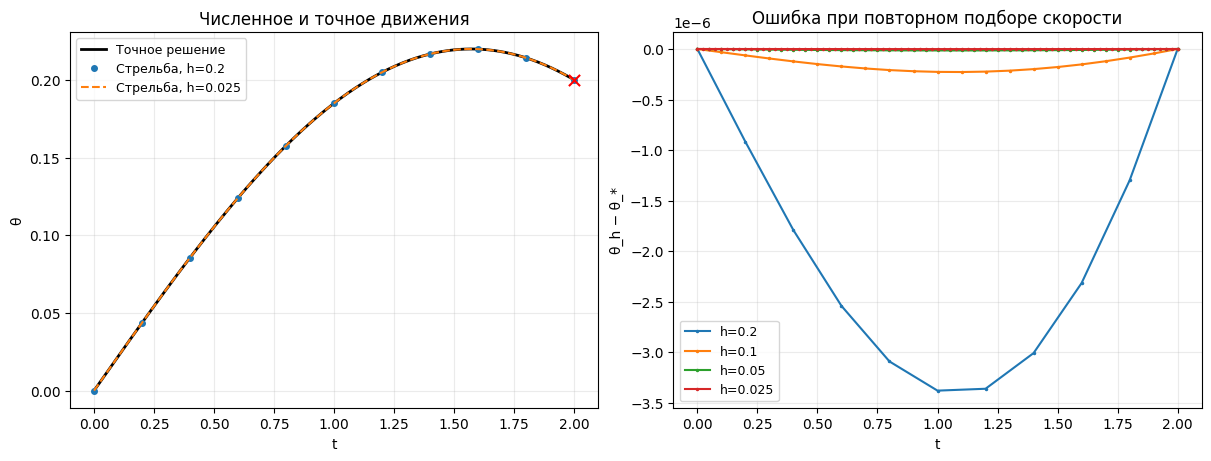

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
time_exact = np.linspace(0.0, T, 501)
axes[0].plot(time_exact, exact_solution(time_exact), color="black", lw=2, label="Точное решение")
for h, style in [(0.2, "o"), (0.025, "--")]:
    result = solutions[("Newton", h)]
    axes[0].plot(result["time"], result["states"][:, 0], style,
                 ms=4, label=f"Стрельба, h={h}")
axes[0].scatter([T], [target], color="red", marker="x", s=65, zorder=5)
axes[0].set_xlabel("t")
axes[0].set_ylabel("θ")
axes[0].set_title("Численное и точное движения")

for h in h_values:
    result = solutions[("Newton", h)]
    axes[1].plot(result["time"], result["error"], marker=".", ms=3, label=f"h={h}")
axes[1].set_xlabel("t")
axes[1].set_ylabel("θ_h − θ_*")
axes[1].set_title("Ошибка при повторном подборе скорости")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)
for ax in axes:
    ax.legend(fontsize=9)
plt.show()


## 5. Почему уменьшение допуска поиска корня не всегда помогает?

Зафиксируем шаг интегрирования $h=0.2$ и изменим только допуск бисекции.
Сравним остаточную невязку и максимальную ошибку движения.

In [10]:
print(f"{'Допуск':>12} {'|R_h|':>14} {'max ошибка θ':>18} {'Вызовы R':>12}")
tolerance_results = []
for tol in [1e-4, 1e-8, 1e-12]:
    result = shoot(0.2, "Bisection", tol)
    tolerance_results.append(result)
    print(f"{tol:12.1e} {abs(result['R']):14.6e} "
          f"{np.max(np.abs(result['error'])):18.6e} {result['calls']:12d}")


      Допуск          |R_h|       max ошибка θ     Вызовы R
     1.0e-04   2.031601e-05       2.045825e-05           13
     1.0e-08   8.524447e-09       3.387106e-06           25
     1.0e-12   3.466949e-13       3.379217e-06           39


## 6. Выводы

Ньютону в этой задаче хватает одной поправки, поскольку невязка линейна по начальной скорости.
Она имеет вид $R_h(s)=A_hs-0.2$, где $A_h$ определяется численным интегрированием.
Всего выполняются четыре вычисления невязки: начальное, два для производной и одно
для проверки нового приближения. Для бисекции при $h=0.2$ и допуске $10^{-12}$
потребовалось $39$ вызовов, включая два конца интервала.

Оба метода дают почти одинаковую скорость при фиксированном $h$.
При уменьшении шага с $0.2$ до $0.025$ ошибка движения снижается примерно
с $3.4\cdot10^{-6}$ до $9.3\cdot10^{-10}$, а подобранная скорость приближается к $s_*$.

Уменьшение допуска поиска корня помогает, пока существенна ошибка подбора скорости.
При $h=0.2$ ужесточение допуска с $10^{-8}$ до $10^{-12}$ уменьшает невязку
примерно с $8.5\cdot10^{-9}$ до $3.5\cdot10^{-13}$, но ошибка движения
остаётся около $3.4\cdot10^{-6}$.
Причина — погрешность интегрирования: ищется корень численной невязки $R_h$,
а не точной $R(s)=s\sin2-0.2$.
Чтобы дальше улучшить движение, нужно уменьшать шаг RK4 и заново подбирать скорость,
а не только ужесточать допуск поиска корня.